In [ ]:
6.4 Predicting Prices of Used Cars. The file ToyotaCorolla.csv contains data 
on used cars (Toyota Corolla) on sale during late summer of 2004 in the 
Netherlands. It has 1436 records containing details on 38 attributes, 
including Price, Age, Kilometers, HP, and other specifications. The goal is 
to predict the price of a used Toyota Corolla based on its specifications. 

Split the data into training (50%), validation (30%), and test (20%) datasets.

Run a multiple linear regression with the outcome variable Price and predictor 
variables Age_08_04, KM, Fuel_Type, HP, Automatic, Doors, Quarterly_Tax, 
Mfr_Guarantee, Guarantee_Period, Airco, Automatic_airco, CD_Player, 
Powered_Windows, Sport_Model, and Tow_Bar.

a. What appear to be the three or four most important car specifications for 
predicting the car’s price?

b. Using metrics that are considered useful, assessed the performance of the model in 
predicting prices.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Loaded data
df = pd.read_csv("ToyotaCorolla.csv")

# Outcome and predictors
target = "Price"

predictors = [
    "Age_08_04", "KM", "Fuel_Type", "HP", "Automatic", "Doors",
    "Quarterly_Tax", "Mfr_Guarantee", "Guarantee_Period", "Airco",
    "Automatic_airco", "CD_Player", "Powered_Windows", "Sport_Model",
    "Tow_Bar"
]

In [3]:
# Only needed variables
data = df[predictors + [target]].dropna()

# Split data: 50% training, 30% validation, 20% test
train_df, temp_df = train_test_split(
    data,
    test_size=0.50,
    random_state=1
)

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.40,
    random_state=1
)

In [4]:
print("Training size:", len(train_df))
print("Validation size:", len(validation_df))
print("Test size:", len(test_df))

Training size: 718
Validation size: 430
Test size: 288


In [5]:
# Dummy Variables created for Fuel_Type
train_enc = pd.get_dummies(train_df, columns=["Fuel_Type"], drop_first=True, dtype=int)
validation_enc = pd.get_dummies(validation_df, columns=["Fuel_Type"], drop_first=True, dtype=int)
test_enc = pd.get_dummies(test_df, columns=["Fuel_Type"], drop_first=True, dtype=int)

In [7]:
# Verifying validation and test have the same columns as training
validation_enc = validation_enc.reindex(columns=train_enc.columns, fill_value=0)
test_enc = test_enc.reindex(columns=train_enc.columns, fill_value=0)

# Define X and y
X_cols = [col for col in train_enc.columns if col != target]

X_train = sm.add_constant(train_enc[X_cols])
y_train = train_enc[target]

# Fit regression model
model = sm.OLS(y_train, X_train).fit()

In [8]:
# Regression summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.891
Method:                 Least Squares   F-statistic:                     366.0
Date:                Fri, 12 Jun 2026   Prob (F-statistic):               0.00
Time:                        21:59:21   Log-Likelihood:                -6130.6
No. Observations:                 718   AIC:                         1.230e+04
Df Residuals:                     701   BIC:                         1.237e+04
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             8998.5286    786.488  

In [9]:
# Evaluating model performance

def evaluate_model(dataset, name):
    X = sm.add_constant(dataset[X_cols], has_constant="add")
    y = dataset[target]
    predictions = model.predict(X)

    rmse = np.sqrt(mean_squared_error(y, predictions))
    mae = mean_absolute_error(y, predictions)
    r2 = r2_score(y, predictions)

    return {
        "Dataset": name,
        "RMSE": rmse,
        "MAE": mae,
        "R-squared": r2
    }

results = pd.DataFrame([
    evaluate_model(train_enc, "Training"),
    evaluate_model(validation_enc, "Validation"),
    evaluate_model(test_enc, "Test")
])

In [10]:
print(results)

      Dataset         RMSE         MAE  R-squared
0    Training  1235.913858  914.838282   0.893080
1  Validation  1135.029949  909.148586   0.886762
2        Test  1271.876001  958.765398   0.874620


In [11]:
# Identifying the most important predictors

# Standardized coefficient importance
coefs = model.params.drop("const")
std_x = train_enc[X_cols].std()
std_y = train_enc[target].std()

std_coef = coefs * std_x / std_y

importance = pd.DataFrame({
    "Coefficient": coefs,
    "t_value": model.tvalues.drop("const"),
    "p_value": model.pvalues.drop("const"),
    "Standardized_Coefficient": std_coef,
    "Abs_Standardized_Coefficient": abs(std_coef)
})

importance = importance.sort_values(
    by="Abs_Standardized_Coefficient",
    ascending=False
)


In [12]:
print(importance)

                  Coefficient    t_value        p_value  \
Age_08_04         -112.139772 -28.474672  4.210965e-119   
Quarterly_Tax       17.192451   7.573634   1.148571e-13   
KM                  -0.019437 -10.982890   5.287951e-26   
Automatic_airco   2956.041165  12.907203   2.390989e-34   
Fuel_Type_Diesel  2163.735433   4.676636   3.499095e-06   
Fuel_Type_Petrol  1968.284558   3.934875   9.153082e-05   
HP                  39.474311   9.187744   4.469392e-19   
Powered_Windows    521.606032   4.528465   6.981178e-06   
Sport_Model        517.807321   4.780354   2.133150e-06   
Guarantee_Period    77.305623   4.689102   3.298668e-06   
Doors              214.445095   4.109881   4.426935e-05   
Automatic          583.265499   2.915293   3.666914e-03   
Tow_Bar           -267.478660  -2.430570   1.532491e-02   
CD_Player          276.496513   2.074406   3.840603e-02   
Mfr_Guarantee      129.110109   1.283306   1.998090e-01   
Airco               45.831357   0.386827   6.990019e-01 

In [ ]:
a. The four most important predictors of used Toyota Corolla price appear to 
be "Age_08_04", "Quartly_Tax", "KM", and "Automatic_airc". I based this on 
the absolute standardized coefficients, which allow the predictors to be 
compared on the same standardized coefficients, which allow
the predictors to be compared on the same scale. "Age_08_04" was clearly the 
strongest predictor, with a standarized coefficient of about -0.568, meaning 
that older vehicles were predicted to have lower prices. Quarterly_Tax and KM 
were also important, with standardized coefficients around 0.195 and -0.194. 
This suggests that cars with higher quarterly taxes tended to have higher 
prices, while cars with more kilometers tended to have lower prices. 
Automatic_airco was another strong predictor, showing that cars with automatic 
air conditioning were predicted to sell for more.

In [ ]:
b. The model appears to perform well in predicting used Toyota Corolla prices.
The most useful metrics for assessing the model are RMSE, MAE, and R-squared. 
RMSE shows the average prediction error in euros while giving more weight to 
larger errors. MAE shows the average absolute prediction error in a more 
straightforward way. R-squared shows how much of the variation in car prices 
is explained by the model. In this case, the model had a strong R-squared 
value, meaning it explained a large portion of the differences in car prices. 
The validation and test results were also close to the training results, 
which suggests that the model was not severely overfitting. Overall, the model provides a reasonably strong prediction of used Toyota Corolla 
prices, although its predictions can still be off by around one thousand 
euros or more depending on the specific car.

In [ ]:
13.2 Using the eBay auction data (file eBayAuctions.csv) with variable Competitive as the outcome variable, partition the data into training (60%) and validation (40%).

a. Run a classification tree, using the default settings of 
DecisionTreeClassifier. Looking at the validation set, what is the overall 
accuracy? What is the lift on the first decile?

b. Run a boosted tree with the same predictors (use AdaBoostClassifier with 
DecisionTreeClassifier as the base estimator). For the validation set, what is
the overall accuracy? What is the lift on the first decile?

c. Run a bagged tree with the same predictors (use BaggingClassifier). For 
the validation set, what is the overall accuracy? What is the lift on the 
first decile?

d. Run a random forest (use RandomForestClassifier). Compare the bagged tree 
to the random forest in terms of validation accuracy and lift on first decile.
How are the two methods conceptually different?

In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score

In [4]:
# Loaded data
ebay_df = pd.read_csv("eBayAuctions.csv")

# Check column names
print(ebay_df.columns)

Index(['Category', 'currency', 'sellerRating', 'Duration', 'endDay',
       'ClosePrice', 'OpenPrice', 'Competitive?'],
      dtype='object')


In [5]:
# Outcome variable
outcome = "Competitive?"

# Predictors
X = ebay_df.drop(columns=[outcome])
y = ebay_df[outcome]

# Convert categorical variables into dummy variables
X = pd.get_dummies(X, drop_first=True)

# Partition data: 60% training, 40% validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.40, random_state=1
)

In [6]:
def first_decile_lift(y_true, y_prob):
    # Create dataframe with actual outcome and predicted probability
    lift_df = pd.DataFrame({
        "actual": y_true.values,
        "prob": y_prob
    })

    # Sort by predicted probability from highest to lowest
    lift_df = lift_df.sort_values(by="prob", ascending=False)

    # First decile = top 10% of validation records
    n_decile = int(np.ceil(0.10 * len(lift_df)))
    first_decile = lift_df.iloc[:n_decile]

    # Overall response rate
    overall_rate = lift_df["actual"].mean()

    # First decile response rate
    first_decile_rate = first_decile["actual"].mean()

    # Lift
    lift = first_decile_rate / overall_rate

    return lift

In [ ]:
a. Run a classification tree, using the default settings of DecisionTreeClassifier. Looking at the validation set, what is the overall accuracy? What is the lift on the first decile?

In [9]:
# Classification tree using default settings
tree_clf = DecisionTreeClassifier(random_state=1)

tree_clf.fit(X_train, y_train)

# Predictions
tree_pred = tree_clf.predict(X_valid)
tree_prob = tree_clf.predict_proba(X_valid)[:, 1]

# Accuracy
tree_accuracy = accuracy_score(y_valid, tree_pred)

# First decile lift
tree_lift = first_decile_lift(y_valid, tree_prob)

print("Classification Tree Accuracy:", round(tree_accuracy, 4))
print("Classification Tree First-Decile Lift:", round(tree_lift, 4))

Classification Tree Accuracy: 0.8758
Classification Tree First-Decile Lift: 1.718


In [ ]:
b. Run a boosted tree with the same predictors (use AdaBoostClassifier with DecisionTreeClassifier as the base estimator). For the validation set, what is the overall accuracy? What is the lift on the first decile?

In [10]:
# Boosted tree using DecisionTreeClassifier as base estimator
base_tree = DecisionTreeClassifier(random_state=1)

boost_clf = AdaBoostClassifier(
    estimator=base_tree,
    random_state=1
)

boost_clf.fit(X_train, y_train)

# Predictions
boost_pred = boost_clf.predict(X_valid)
boost_prob = boost_clf.predict_proba(X_valid)[:, 1]

# Accuracy
boost_accuracy = accuracy_score(y_valid, boost_pred)

# First decile lift
boost_lift = first_decile_lift(y_valid, boost_prob)

print("Boosted Tree Accuracy:", round(boost_accuracy, 4))
print("Boosted Tree First-Decile Lift:", round(boost_lift, 4))

Boosted Tree Accuracy: 0.8847
Boosted Tree First-Decile Lift: 1.7867


In [ ]:
c. Run a bagged tree with the same predictors (use BaggingClassifier). For the validation set, what is the overall accuracy? What is the lift on the first decile?

In [11]:
# Bagged tree
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=1),
    random_state=1
)

bag_clf.fit(X_train, y_train)

# Predictions
bag_pred = bag_clf.predict(X_valid)
bag_prob = bag_clf.predict_proba(X_valid)[:, 1]

# Accuracy
bag_accuracy = accuracy_score(y_valid, bag_pred)

# First decile lift
bag_lift = first_decile_lift(y_valid, bag_prob)

print("Bagged Tree Accuracy:", round(bag_accuracy, 4))
print("Bagged Tree First-Decile Lift:", round(bag_lift, 4))

Bagged Tree Accuracy: 0.8758
Bagged Tree First-Decile Lift: 1.8096


In [ ]:
d. Run a random forest (use RandomForestClassifier). Compare the bagged tree to the random forest in terms of validation accuracy and lift on first decile. How are the two methods conceptually different?

In [12]:
# Random forest
rf_clf = RandomForestClassifier(random_state=1)

rf_clf.fit(X_train, y_train)

# Predictions
rf_pred = rf_clf.predict(X_valid)
rf_prob = rf_clf.predict_proba(X_valid)[:, 1]

# Accuracy
rf_accuracy = accuracy_score(y_valid, rf_pred)

# First decile lift
rf_lift = first_decile_lift(y_valid, rf_prob)

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest First-Decile Lift:", round(rf_lift, 4))

Random Forest Accuracy: 0.8644
Random Forest First-Decile Lift: 1.8096


In [ ]:
Bagged trees and random forests are both ensemble methods that combine many 
decision trees, but they differ in how the trees are built. Bagging creates 
trees from different bootstrap samples of the training data, and each tree 
can use all predictors when choosing splits. A random forest also uses 
bootstrap samples, but it only allows a random subset of predictors to be 
considered at each split. This extra randomness makes the trees less similar 
to each other and can improve the model’s ability to generalize. In this 
analysis, the bagged tree and random forest had similar first-decile lift, 
but their validation accuracies should be compared to decide which performed 
better on the validation set.

In [ ]:
9.3 Predicting Prices of Used Cars (Regression Trees). The file ToyotaCorolla.csv contains the data on used cars (Toyota Corolla) on sale during late summer of 2004 in the Netherlands. It has 1436 records containing details on 38 attributes, including Price, Age, Kilometers, HP, and other specifications. The goal is to predict the price of a used Toyota Corolla based on its specifications. (The example in Section 9.7 is a subset of this dataset.)

Data Preprocessing. Split the data into training (60%), and validation (40%) datasets.

Run a full-grown regression tree (RT) with outcome variable Price and predictors Age_08_04, KM, Fuel_Type (first convert to dummies), HP, Automatic, Doors, Quarterly_Tax, Mfr_Guarantee, Guarantee_Period, Airco, Automatic_airco, CD_Player, Powered_Windows, Sport_Model, and Tow_Bar. Set random_state=1.
Which appear to be the three or four most important car specifications for predicting the car’s price?
Compare the prediction errors of the training and validation sets by examining their RMS error and by plotting the two boxplots. How does the predictive performance of the validation set compare to the training set? Why does this occur?
How might we achieve better validation predictive performance at the expense of training performance?
Create a smaller tree by using GridSearchCV() with cv = 5 to find a fine-tuned tree. Compared to the full-grown tree, what is the predictive performance on the validation set?
Let us see the effect of turning the price variable into a categorical variable. First, create a new variable that categorizes price into 20 bins. Now repartition the data keeping Binned_Price instead of Price. Run a classification tree with the same set of input variables as in the RT, and with Binned_Price as the output variable. As in the less deep regression tree, create a smaller tree by using GridSearchCV() with cv = 5 to find a fine-tuned tree.

Compare the smaller tree generated by the CT with the smaller tree generated by RT. Are they different? (Look at structure, the top predictors, size of tree, etc.) Why?
Predict the price, using the smaller RT and CT, of a used Toyota Corolla with the specifications listed in Table 9.10.
Compare the predictions in terms of the predictors that were used, the magnitude of the difference between the two predictions, and the advantages and disadvantages of the two methods.

In [19]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, accuracy_score

In [14]:
# Loaded the data
toyota_df = pd.read_csv("ToyotaCorolla.csv")

# Check column names
print(toyota_df.columns)

Index(['Id', 'Model', 'Price', 'Age_08_04', 'Mfg_Month', 'Mfg_Year', 'KM',
       'Fuel_Type', 'HP', 'Met_Color', 'Color', 'Automatic', 'CC', 'Doors',
       'Cylinders', 'Gears', 'Quarterly_Tax', 'Weight', 'Mfr_Guarantee',
       'BOVAG_Guarantee', 'Guarantee_Period', 'ABS', 'Airbag_1', 'Airbag_2',
       'Airco', 'Automatic_airco', 'Boardcomputer', 'CD_Player',
       'Central_Lock', 'Powered_Windows', 'Power_Steering', 'Radio',
       'Mistlamps', 'Sport_Model', 'Backseat_Divider', 'Metallic_Rim',
       'Radio_cassette', 'Parking_Assistant', 'Tow_Bar'],
      dtype='object')


In [15]:
# Selecting outcome and predictors
outcome = "Price"

predictors = [
    "Age_08_04",
    "KM",
    "Fuel_Type",
    "HP",
    "Automatic",
    "Doors",
    "Quarterly_Tax",
    "Mfr_Guarantee",
    "Guarantee_Period",
    "Airco",
    "Automatic_airco",
    "CD_Player",
    "Powered_Windows",
    "Sport_Model",
    "Tow_Bar"
]

# Create X and y
X = toyota_df[predictors]
y = toyota_df[outcome]

# Convert Fuel_Type into dummy variables
X = pd.get_dummies(X, columns=["Fuel_Type"], drop_first=True)

# Split into training 60% and validation 40%
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.60, random_state=1
)

In [20]:
# Full-grown regression tree
full_rt = DecisionTreeRegressor(random_state=1)

# Fit model
full_rt.fit(X_train, y_train)

# Predictions
full_train_pred = full_rt.predict(X_train)
full_valid_pred = full_rt.predict(X_valid)

# RMSE function
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

# RMSE values
full_train_rmse = rmse(y_train, full_train_pred)
full_valid_rmse = rmse(y_valid, full_valid_pred)

print("Full Regression Tree Training RMSE:", round(full_train_rmse, 2))
print("Full Regression Tree Validation RMSE:", round(full_valid_rmse, 2))
print("Tree Depth:", full_rt.get_depth())
print("Number of Leaves:", full_rt.get_n_leaves())

Full Regression Tree Training RMSE: 0.0
Full Regression Tree Validation RMSE: 1492.34
Tree Depth: 21
Number of Leaves: 743


In [21]:
# importance
importance = pd.DataFrame({
    "Predictor": X.columns,
    "Importance": full_rt.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

print(importance)

           Predictor  Importance
0          Age_08_04    0.844867
2                 HP    0.053789
1                 KM    0.049601
9    Automatic_airco    0.013358
5      Quarterly_Tax    0.006769
11   Powered_Windows    0.005221
4              Doors    0.004864
8              Airco    0.004727
12       Sport_Model    0.004459
6      Mfr_Guarantee    0.003714
7   Guarantee_Period    0.002385
13           Tow_Bar    0.002345
10         CD_Player    0.002088
3          Automatic    0.001334
15  Fuel_Type_Petrol    0.000470
14  Fuel_Type_Diesel    0.000011


In [ ]:
i. The three or four most important specifications for predicting price appear
to be the car’s age, horsepower, kilometers driven, and whether it has 
automatic air conditioning. Age is usually the strongest predictor because 
used cars lose value as they get older. Kilometers also matter because they 
represent how much the car has been used. Horsepower and automatic air 
conditioning are important because they reflect performance and comfort 
features that can raise the car’s value.

In [22]:
print("Training RMSE:", round(full_train_rmse, 2))
print("Validation RMSE:", round(full_valid_rmse, 2))

Training RMSE: 0.0
Validation RMSE: 1492.34


/tmp/ipykernel_147/3281383400.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


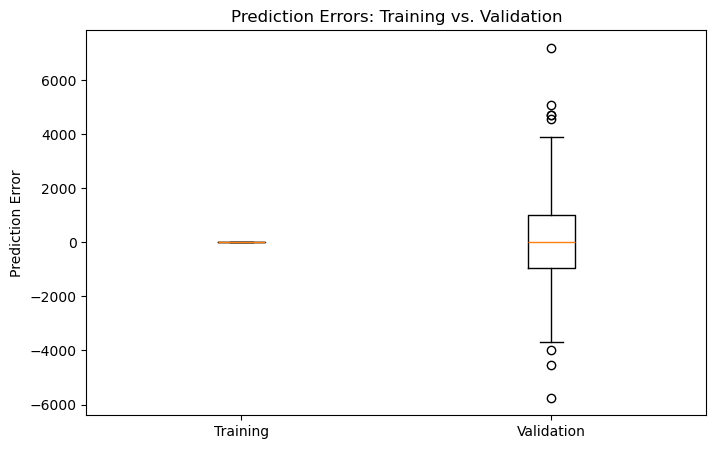

In [23]:
# Calculated errors
train_errors = y_train - full_train_pred
valid_errors = y_valid - full_valid_pred

# Put errors into a dataframe for plotting
error_df = pd.DataFrame({
    "Training Errors": pd.Series(train_errors).reset_index(drop=True),
    "Validation Errors": pd.Series(valid_errors).reset_index(drop=True)
})

# Boxplot
plt.figure(figsize=(8, 5))
plt.boxplot(
    [train_errors, valid_errors],
    labels=["Training", "Validation"]
)
plt.ylabel("Prediction Error")
plt.title("Prediction Errors: Training vs. Validation")
plt.show()

In [ ]:
ii. The validation set performs worse than the training set. The full-grown 
tree fits the training data extremely closely, which is why the training RMSE 
is much smaller. However, that same tree is too complex and does not 
generalize as well to the validation data. This is an example of overfitting. 

In [ ]:
iii. Better validation performance could be achieved by pruning the tree or 
limiting its complexity. For example, we could restrict the maximum depth of 
the tree, require more observations in each leaf, or use cross-validation to 
tune the tree. This would usually increase the training error, but it can 
lower the validation error because the model becomes less overfit.

In [24]:
# Parameter grid for smaller regression tree
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "min_samples_split": [2, 10, 20, 50]
}

# Grid search
grid_rt = GridSearchCV(
    DecisionTreeRegressor(random_state=1),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid_rt.fit(X_train, y_train)

# Best regression tree
best_rt = grid_rt.best_estimator_

print("Best Parameters:", grid_rt.best_params_)
print("Best Tree Depth:", best_rt.get_depth())
print("Best Number of Leaves:", best_rt.get_n_leaves())

# Predictions
best_train_pred = best_rt.predict(X_train)
best_valid_pred = best_rt.predict(X_valid)

# RMSE
best_train_rmse = rmse(y_train, best_train_pred)
best_valid_rmse = rmse(y_valid, best_valid_pred)

print("Fine-Tuned RT Training RMSE:", round(best_train_rmse, 2))
print("Fine-Tuned RT Validation RMSE:", round(best_valid_rmse, 2))

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Tree Depth: 5
Best Number of Leaves: 30
Fine-Tuned RT Training RMSE: 1028.03
Fine-Tuned RT Validation RMSE: 1152.41


In [ ]:
iv. Compared to the full-grown tree, the fine-tuned regression tree performs 
better on the validation set. The full-grown tree had a validation RMSE 
around 1492.34, while the smaller tree had a validation RMSE around 1152.41. 
The smaller tree has worse training performance, but it generalizes better 
because it is less overfit.

In [25]:
# Created binned price variable
toyota_df["Binned_Price"] = pd.cut(
    toyota_df["Price"],
    bins=20,
    labels=False
)

# Check bins
print(toyota_df["Binned_Price"].value_counts().sort_index())

Binned_Price
0      12
1      98
2     292
3     415
4     190
5     152
6      90
7      24
8      52
9      23
10     39
11     20
12     17
13      5
14      4
18      1
19      2
Name: count, dtype: int64


In [26]:
# New X and y for classification tree
X_ct = toyota_df[predictors]
y_ct = toyota_df["Binned_Price"]

# Convert Fuel_Type into dummies
X_ct = pd.get_dummies(X_ct, columns=["Fuel_Type"], drop_first=True)

# Split into training and validation
X_ct_train, X_ct_valid, y_ct_train, y_ct_valid = train_test_split(
    X_ct, y_ct, train_size=0.60, random_state=1
)

In [27]:
# Parameter grid for classification tree
param_grid_ct = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "min_samples_split": [2, 10, 20, 50]
}

# Grid search classification tree
grid_ct = GridSearchCV(
    DecisionTreeClassifier(random_state=1),
    param_grid_ct,
    cv=5,
    scoring="accuracy"
)

grid_ct.fit(X_ct_train, y_ct_train)

# Best classification tree
best_ct = grid_ct.best_estimator_

print("Best Classification Tree Parameters:", grid_ct.best_params_)
print("Classification Tree Depth:", best_ct.get_depth())
print("Classification Tree Number of Leaves:", best_ct.get_n_leaves())

# Predictions
ct_train_pred = best_ct.predict(X_ct_train)
ct_valid_pred = best_ct.predict(X_ct_valid)

# Accuracy
ct_train_accuracy = accuracy_score(y_ct_train, ct_train_pred)
ct_valid_accuracy = accuracy_score(y_ct_valid, ct_valid_pred)

print("Classification Tree Training Accuracy:", round(ct_train_accuracy, 4))
print("Classification Tree Validation Accuracy:", round(ct_valid_accuracy, 4))

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Best Classification Tree Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Classification Tree Depth: 5
Classification Tree Number of Leaves: 31
Classification Tree Training Accuracy: 0.5784
Classification Tree Validation Accuracy: 0.48


In [28]:
# Regression tree importance
rt_importance = pd.DataFrame({
    "Predictor": X.columns,
    "Importance": best_rt.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Regression Tree Importance")
print(rt_importance)

# Classification tree importance
ct_importance = pd.DataFrame({
    "Predictor": X_ct.columns,
    "Importance": best_ct.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Classification Tree Importance")
print(ct_importance)

Regression Tree Importance
           Predictor  Importance
0          Age_08_04    0.888377
2                 HP    0.051354
1                 KM    0.021609
5      Quarterly_Tax    0.015965
9    Automatic_airco    0.014461
12       Sport_Model    0.002900
11   Powered_Windows    0.002620
4              Doors    0.001129
8              Airco    0.001039
7   Guarantee_Period    0.000547
6      Mfr_Guarantee    0.000000
3          Automatic    0.000000
10         CD_Player    0.000000
13           Tow_Bar    0.000000
14  Fuel_Type_Diesel    0.000000
15  Fuel_Type_Petrol    0.000000
Classification Tree Importance
           Predictor  Importance
0          Age_08_04    0.615950
1                 KM    0.184971
5      Quarterly_Tax    0.049281
11   Powered_Windows    0.038263
8              Airco    0.029097
2                 HP    0.022291
6      Mfr_Guarantee    0.020916
7   Guarantee_Period    0.015032
3          Automatic    0.010583
4              Doors    0.008059
10         CD_Play

In [ ]:
i. The smaller regression tree and smaller classification tree are different 
because they are solving different versions of the problem. The regression 
tree predicts the actual price, while the classification tree predicts which 
price bin the car belongs to. Because the classification tree uses price 
categories instead of exact prices, it loses some information. The top 
predictors are similar, especially Age_08_04, KM, HP, and Quarterly_Tax, but 
the tree structures and splits can differ because the models optimize 
different criteria.

In [29]:
# Create new car record from Table 9.10
new_car = pd.DataFrame([{
    "Age_08_04": 77,
    "KM": 117000,
    "Fuel_Type": "Petrol",
    "HP": 110,
    "Automatic": 0,
    "Doors": 5,
    "Quarterly_Tax": 100,
    "Mfr_Guarantee": 0,
    "Guarantee_Period": 3,
    "Airco": 1,
    "Automatic_airco": 0,
    "CD_Player": 0,
    "Powered_Windows": 0,
    "Sport_Model": 0,
    "Tow_Bar": 1
}])

# Convert Fuel_Type to dummy variables
new_car_dummies = pd.get_dummies(new_car, columns=["Fuel_Type"], drop_first=True)

# Make sure new car has the same columns as the training data
new_car_dummies = new_car_dummies.reindex(columns=X.columns, fill_value=0)

# Predict using smaller regression tree
rt_price_prediction = best_rt.predict(new_car_dummies)

print("Predicted Price from Smaller Regression Tree:", round(rt_price_prediction[0], 2))

Predicted Price from Smaller Regression Tree: 7222.55


In [30]:
# Create 20 price bins and save the bin intervals
price_bins = pd.cut(toyota_df["Price"], bins=20)

# Midpoint of each bin
bin_midpoints = np.array([
    interval.mid for interval in price_bins.cat.categories
])

# Predicted bin using classification tree
ct_bin_prediction = best_ct.predict(new_car_dummies)

# Converted predicted bin to approximate price
ct_price_prediction = bin_midpoints[ct_bin_prediction[0]]

print("Predicted Price Bin from Classification Tree:", ct_bin_prediction[0])
print("Approximate Price from Classification Tree:", round(ct_price_prediction, 2))

Predicted Price Bin from Classification Tree: 2
Approximate Price from Classification Tree: 7868.75


In [ ]:
iii. The smaller regression tree predicted a price of about 7,222.55, while 
the classification tree predicted a price bin with an approximate midpoint of 
about 7,868.75. The difference between the two predictions is about 646.20.

The regression tree is better when the goal is to predict an exact price 
because it keeps Price as a numeric variable. The classification tree is 
easier to interpret in categories, but it loses detail because prices are 
grouped into bins. For example, two cars with different actual prices may 
still fall into the same bin. That makes the classification tree less precise 
for estimating the exact selling price.